# 01. EDA dan Preprocessing

Notebook ini menyiapkan data untuk klasifikasi katarak (Normal vs Katarak) pada citra fundus ODIR-5K.

**Langkah**
1. Muat anotasi dan lihat distribusi label.
2. Pilih data di level mata dengan aturan seleksi yang ketat.
3. Lakukan EDA pada data hasil seleksi.
4. Bagi data menjadi train, val, dan test per pasien.
5. Terapkan CLAHE dengan mask fundus.
6. Simpan cache citra hasil CLAHE.

**Keluaran**
- `results/splits/{train,val,test}.csv`: daftar citra tiap split.
- `results/split_summary.csv`: ringkasan jumlah citra per split.
- `data/processed/*.npy`: citra CLAHE (uint8) untuk notebook 02 dan 03. Folder ini tidak masuk Git.
- `images/eda_distribusi.png` dan `images/clahe_mask.png`: gambar untuk README.

**Prasyarat:** dataset ODIR-5K berada di `data/ODIR-5K/` atau path-nya diatur lewat variabel lingkungan `ODIR_DATASET_PATH`. Lihat `data/README.md`.

In [4]:
import sys
from pathlib import Path

# Notebook dijalankan dari folder notebooks/. Akar repositori ada satu tingkat di atasnya.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings

import numpy as np
import pandas as pd

from src import config, data, preprocessing, visualization
from src.utils import set_seed

warnings.filterwarnings("ignore")
set_seed(config.SEED)

def cek(path):
    return "ada" if path.exists() else "TIDAK ADA"

print("Dataset :", config.DATASET_PATH)
print("Anotasi :", config.ANNO_FILE, f"({cek(config.ANNO_FILE)})")
print("Citra   :", config.IMG_DIR, f"({cek(config.IMG_DIR)})")

Dataset : <ROOT>\data\ODIR-5K
Anotasi : <ROOT>\data\ODIR-5K\data.xlsx (ada)
Citra   : <ROOT>\data\ODIR-5K\Images (ada)


## 1. Muat anotasi

In [5]:
df_raw = data.load_annotations()
print(f"Total pasien  : {len(df_raw):,}")
print(f"Kolom dataset : {df_raw.columns.tolist()}")
df_raw.head()

Total pasien  : 3,500
Kolom dataset : ['ID', 'Patient Age', 'Patient Sex', 'Left-Fundus', 'Right-Fundus', 'Left-Diagnostic Keywords', 'Right-Diagnostic Keywords', 'N', 'D', 'G', 'C', 'A', 'H', 'M', 'O']


,ID,Patient Age,Patient Sex,Left-Fundus,Right-Fundus,Left-Diagnostic Keywords,Right-Diagnostic Keywords,N,D,G,C,A,H,M,O
0,0,69,Female,0_left.jpg,0_right.jpg,cataract,normal fundus,0,0,0,1,0,0,0,0
1,1,57,Male,1_left.jpg,1_right.jpg,normal fundus,normal fundus,1,0,0,0,0,0,0,0
2,2,42,Male,2_left.jpg,2_right.jpg,laser spot，moderate non proliferative retinopathy,moderate non proliferative retinopathy,0,1,0,0,0,0,0,1
3,3,66,Male,3_left.jpg,3_right.jpg,normal fundus,branch retinal artery occlusion,0,0,0,0,0,0,0,1
4,4,53,Male,4_left.jpg,4_right.jpg,macular epiretinal membrane,mild nonproliferative retinopathy,0,1,0,0,0,0,0,1


Distribusi label di level pasien. Satu pasien dapat memiliki lebih dari satu label.

In [6]:
data.label_distribution(df_raw)

,kode,kelas,jumlah_pasien
0,N,Normal,1140
1,D,Retinopati Diabetik,1128
2,G,Glaukoma,215
3,C,Katarak,212
4,A,AMD,164
5,H,Hipertensi Retina,103
6,M,Miopia Patologis,174
7,O,Penyakit Lain,979


## 2. Seleksi data level mata

Satu baris pasien diubah menjadi dua baris mata (kiri dan kanan). Aturan seleksinya:

| Kondisi | Label |
|---|---|
| Keyword mengandung `cataract` | 1 (Katarak) |
| Keyword persis `normal fundus` | 0 (Normal) |
| Penyakit lain, `lens dust` tanpa `cataract`, keyword campuran, atau kosong | Dikeluarkan |
| Mata normal milik pasien katarak (C=1) | Dikeluarkan |

Alasan aturan terakhir: mata yang tampak normal pada pasien katarak unilateral dapat memiliki perubahan subklinis. Mata itu berisiko mencemari kelas Normal.

Alasan `lens dust` dikeluarkan: kekeruhan akibat debu lensa mirip katarak secara visual. Jika masuk kelas Normal, label itu menambah noise pada batas keputusan.

In [7]:
df_eye = data.extract_records_eye_level(
    df_raw,
    exclude_normal_of_cataract_patient=True,   # ubah ke False untuk membandingkan
)
df_eye = data.add_image_path(df_eye)
df_eye.head()

  HASIL SELEKSI DATA LEVEL MATA
  Total mata lolos          :   3081
  |- Katarak (label=1)      :    313
  |- Normal  (label=0)      :   2768
  Rasio Normal:Katarak      :   1:8.84
----------------------------------------------------
  Dieksklusi penyakit lain  :   3871
  Dieksklusi label bocor    :     48 
  Dieksklusi file hilang    :      0

  OK: tidak ada tumpang-tindih pasien antar kelas.


,patient_id,filename,side,label,age,sex,keyword,img_path
0,0,0_left.jpg,L,1,69,Female,cataract,\data\ODIR-5K\Images\0_left.jpg
1,1,1_left.jpg,L,0,57,Male,normal fundus,\data\ODIR-5K\Images\1_left.jpg
2,1,1_right.jpg,R,0,57,Male,normal fundus,\data\ODIR-5K\Images\1_right.jpg
3,3,3_left.jpg,L,0,66,Male,normal fundus,\data\ODIR-5K\Images\3_left.jpg
4,8,8_left.jpg,L,0,59,Male,normal fundus,\data\ODIR-5K\Images\8_left.jpg


## 3. Exploratory Data Analysis

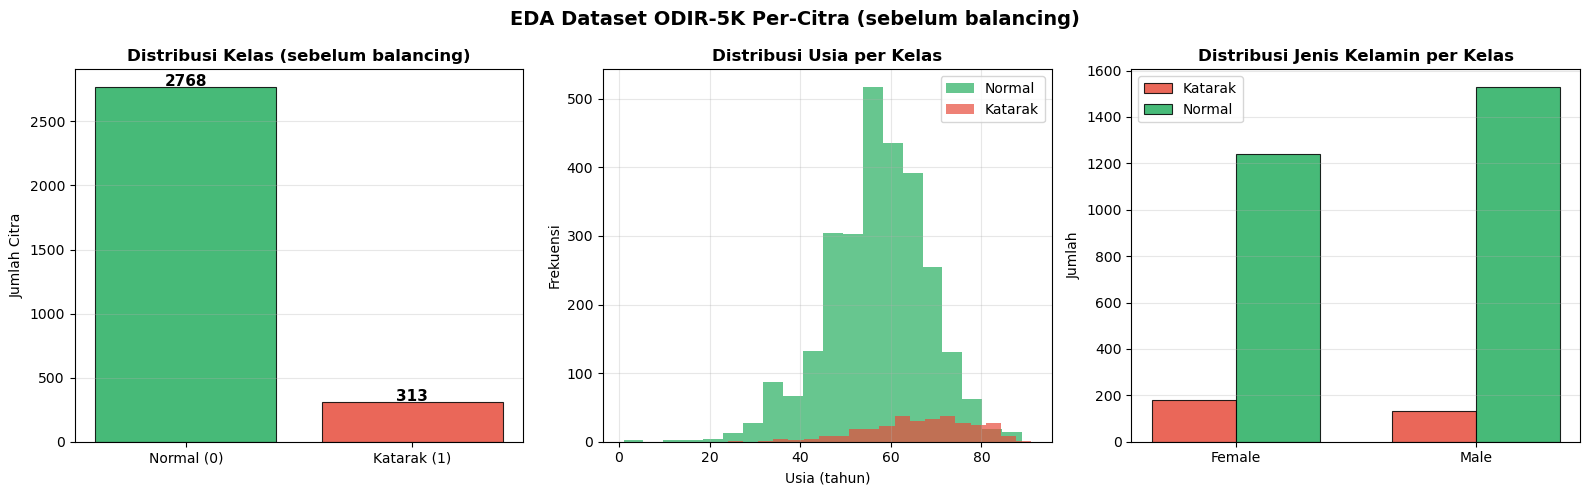

In [8]:
visualization.plot_eda(df_eye, save_path=config.IMAGES_DIR / "eda_distribusi.png")

## 4. Split per pasien

Setiap pasien punya dua mata. Split dilakukan di level `patient_id`, sehingga mata kiri dan kanan pasien yang sama tidak terpisah ke train dan test.

Split dilakukan **sebelum** balancing. Val dan test mempertahankan rasio kelas asli, jadi metrik tidak membesar karena data evaluasi yang seimbang secara buatan.

In [9]:
df_train, df_val, df_test = data.make_splits(df_eye)

ids = [set(d["patient_id"]) for d in (df_train, df_val, df_test)]
assert not (ids[0] & ids[1]) and not (ids[0] & ids[2]) and not (ids[1] & ids[2]), \
    "Ada pasien yang muncul di lebih dari satu split."
print("OK: tidak ada pasien yang muncul di lebih dari satu split.\n")

summary = data.split_summary(df_train, df_val, df_test)
summary

OK: tidak ada pasien yang muncul di lebih dari satu split.



,split,total,katarak,normal,rasio_normal_katarak
0,Train,2153,221,1932,8.74
1,Val,466,47,419,8.91
2,Test,462,45,417,9.27


In [10]:
data.save_splits(df_train, df_val, df_test)
summary.to_csv(config.RESULTS_DIR / "split_summary.csv", index=False)
print("Split disimpan di:", config.SPLITS_DIR)

Split disimpan di: <ROOT>\results\splits


## 5. Preprocessing CLAHE dengan mask fundus

Pipeline per citra:
1. **Resize** ke 224 x 224 piksel.
2. **Mask fundus**: ambang piksel > 5, lalu closing dan opening dengan kernel elips 9 x 9.
3. **CLAHE** pada kanal L (ruang warna Lab). Clip limit 2,0 dan tile 8 x 8, sehingga ukuran tile 28 x 28 piksel. Background hitam diisi sementara dengan median L area fundus, lalu dikembalikan ke hitam.
4. **Normalisasi piksel** khusus tiap backbone. Langkah ini ada di notebook 02, bukan di sini. ResNet50 memakai `preprocess_input` mode caffe. EfficientNet-B0 menormalisasi di dalam backbone.

Dengan begitu, satu cache citra CLAHE melayani kedua model.

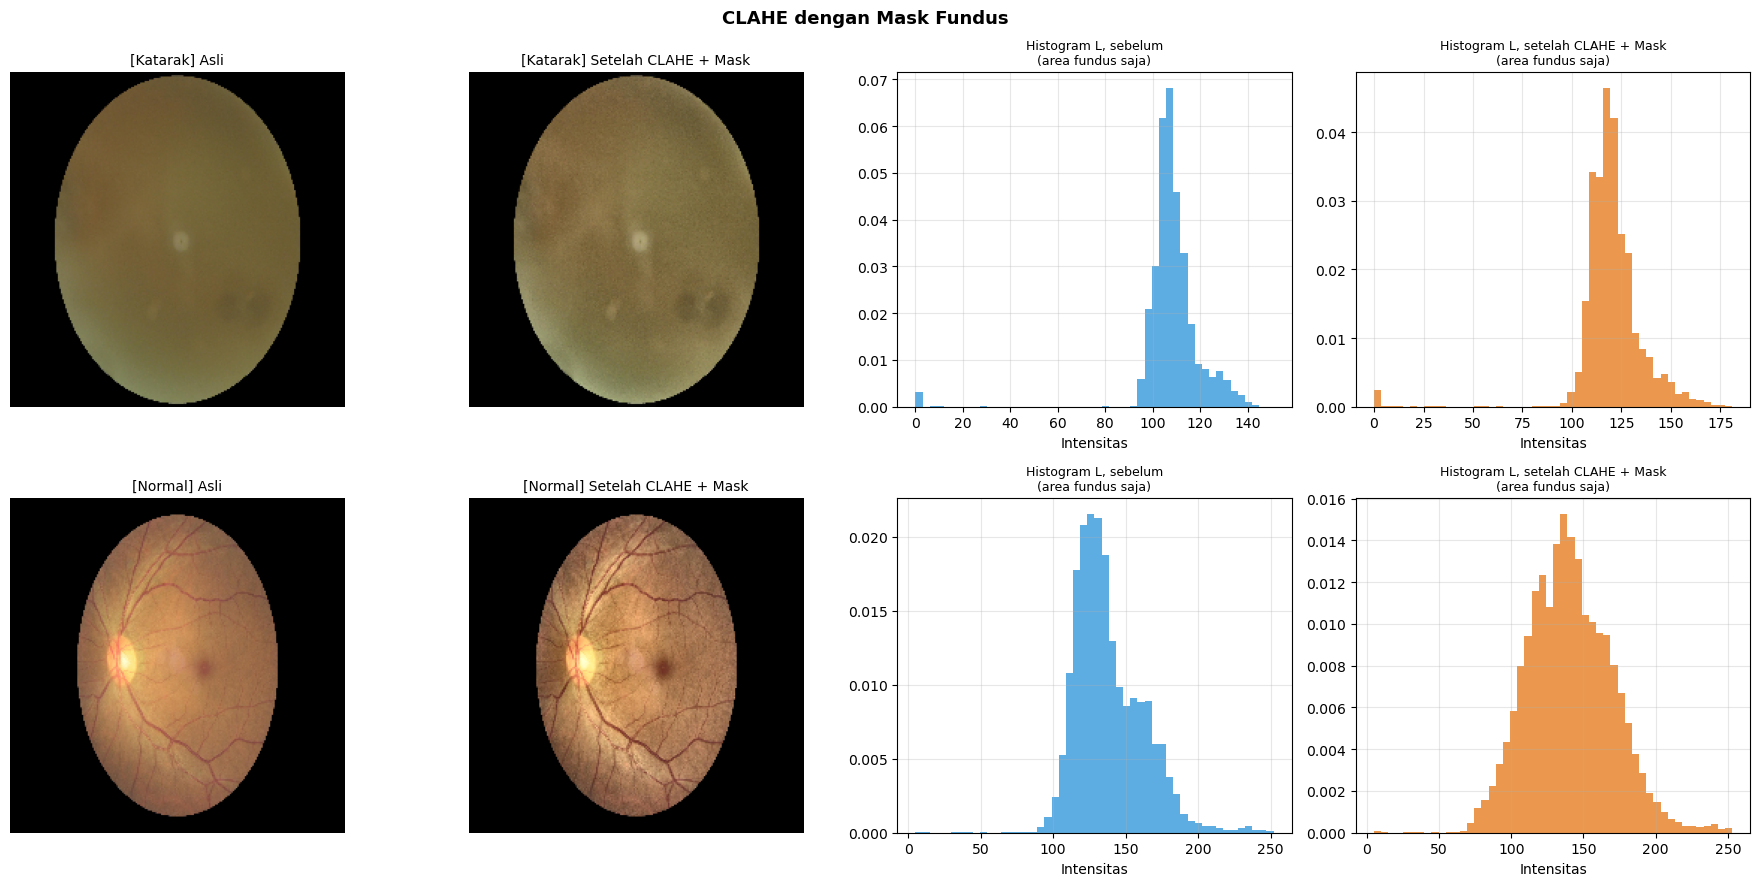

In [11]:
sample_paths = [
    df_eye.loc[df_eye["label"] == 1, "img_path"].iloc[0],
    df_eye.loc[df_eye["label"] == 0, "img_path"].iloc[0],
]
visualization.plot_clahe_comparison(
    sample_paths, ["Katarak", "Normal"],
    save_path=config.IMAGES_DIR / "clahe_mask.png",
)

## 6. Muat semua citra dan simpan cache

Tiap split dimuat terpisah. Hasil CLAHE disimpan sebagai `uint8` agar ukuran cache kecil. Notebook 02 dan 03 membaca cache ini, jadi CLAHE tidak dihitung ulang.

In [12]:
rows = []
for name, df_ in [("train", df_train), ("val", df_val), ("test", df_test)]:
    X, y = preprocessing.load_split_images(df_, desc=name)
    preprocessing.save_cache(name, X, y)
    rows.append({"split": name, "shape": str(X.shape), "dtype": str(X.dtype),
                 "katarak": int((y == 1).sum()), "normal": int((y == 0).sum()),
                 "ukuran_MB": round(X.nbytes / 1024**2, 1)})
    del X, y

pd.DataFrame(rows)

,split,shape,dtype,katarak,normal,ukuran_MB
0,train,"(2153, 224, 224, 3)",uint8,221,1932,309.1
1,val,"(466, 224, 224, 3)",uint8,47,419,66.9
2,test,"(462, 224, 224, 3)",uint8,45,417,66.3
